# 🛠️ 03 - Titanic Feature Engineering

This notebook creates predictive domain features to enhance machine learning model performance.

### Engineered Features:
1. **`Title`**: Social status and demographic role extracted from passenger names (`Mr`, `Mrs`, `Miss`, `Master`, `Officer`, `Royalty`).
2. **`FamilySize`**: Total family members aboard (`SibSp + Parch + 1`).
3. **`IsAlone`**: Binary indicator (1 if traveling solo, 0 otherwise).
4. **`FarePerPerson`**: Normalized individual ticket expenditure (`Fare / FamilySize`).
5. **`AgeGroup`**: Discretized age brackets (`Child`, `Teen`, `YoungAdult`, `MiddleAged`, `Senior`).
6. **`FareBin`**: Discretized fare brackets (`Low`, `MidLow`, `MidHigh`, `High`).
7. **`Deck`**: Cabin deck classification.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path("..").resolve()))
from src.data_loader import load_raw_data, save_processed_data
from src.preprocessing import TitanicPreprocessor
from src.feature_engineering import TitanicFeatureEngineer

# Load raw and clean
raw_df = load_raw_data("../data/raw/train.csv")
preprocessor = TitanicPreprocessor()
cleaned_df = preprocessor.fit_transform(raw_df)

# Feature engineering
fe = TitanicFeatureEngineer(drop_raw_cols=False)
engineered_df = fe.transform(cleaned_df)
print(f"Engineered Dataset Shape: {engineered_df.shape}")
engineered_df.head()


Engineered Dataset Shape: (891, 19)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Deck,FamilySize,IsAlone,FarePerPerson,AgeGroup,FareBin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,Mr,Unknown,2,0,3.62500,YoungAdult,Low
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,C,2,0,35.64165,MiddleAged,High
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,Miss,Unknown,1,1,7.92500,YoungAdult,MidLow
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,C,2,0,26.55000,YoungAdult,High
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,Mr,Unknown,1,1,8.05000,YoungAdult,MidLow


## 1. Feature Analysis: Family Dynamics (`FamilySize` & `IsAlone`)

C:\Users\Sagar\AppData\Local\Temp\ipykernel_11172\3856003318.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engineered_df, x="FamilySize", y="Survived", palette="Blues_r", ax=axes[0])


C:\Users\Sagar\AppData\Local\Temp\ipykernel_11172\3856003318.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engineered_df, x="IsAlone", y="Survived", palette=["#EF4444", "#10B981"], ax=axes[1])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_11172\3856003318.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["With Family", "Alone"])


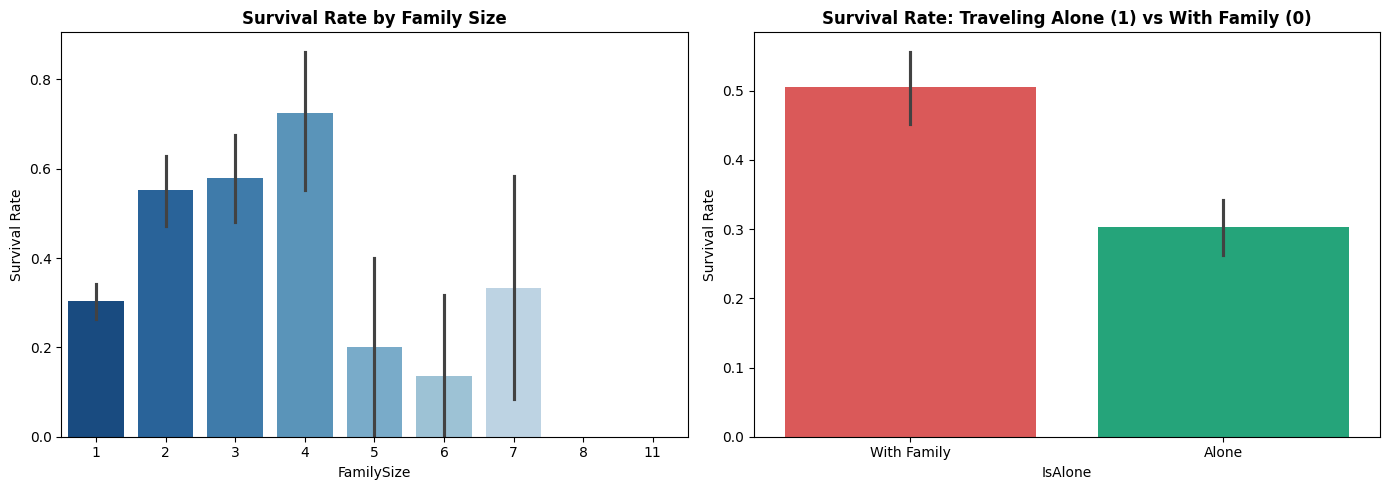

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Family Size vs Survival
sns.barplot(data=engineered_df, x="FamilySize", y="Survived", palette="Blues_r", ax=axes[0])
axes[0].set_title("Survival Rate by Family Size", fontweight="bold")
axes[0].set_ylabel("Survival Rate")

# IsAlone vs Survival
sns.barplot(data=engineered_df, x="IsAlone", y="Survived", palette=["#EF4444", "#10B981"], ax=axes[1])
axes[1].set_title("Survival Rate: Traveling Alone (1) vs With Family (0)", fontweight="bold")
axes[1].set_ylabel("Survival Rate")
axes[1].set_xticklabels(["With Family", "Alone"])

plt.tight_layout()
plt.show()


## 2. Feature Analysis: Passenger Title & Deck

C:\Users\Sagar\AppData\Local\Temp\ipykernel_11172\2503546099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engineered_df, x="Title", y="Survived", palette="Blues_r", ax=axes[0])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_11172\2503546099.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engineered_df, x="Deck", y="Survived", order=["A", "B", "C", "D", "E", "F", "G", "Unknown"], palette="Blues_r", ax=axes[1])


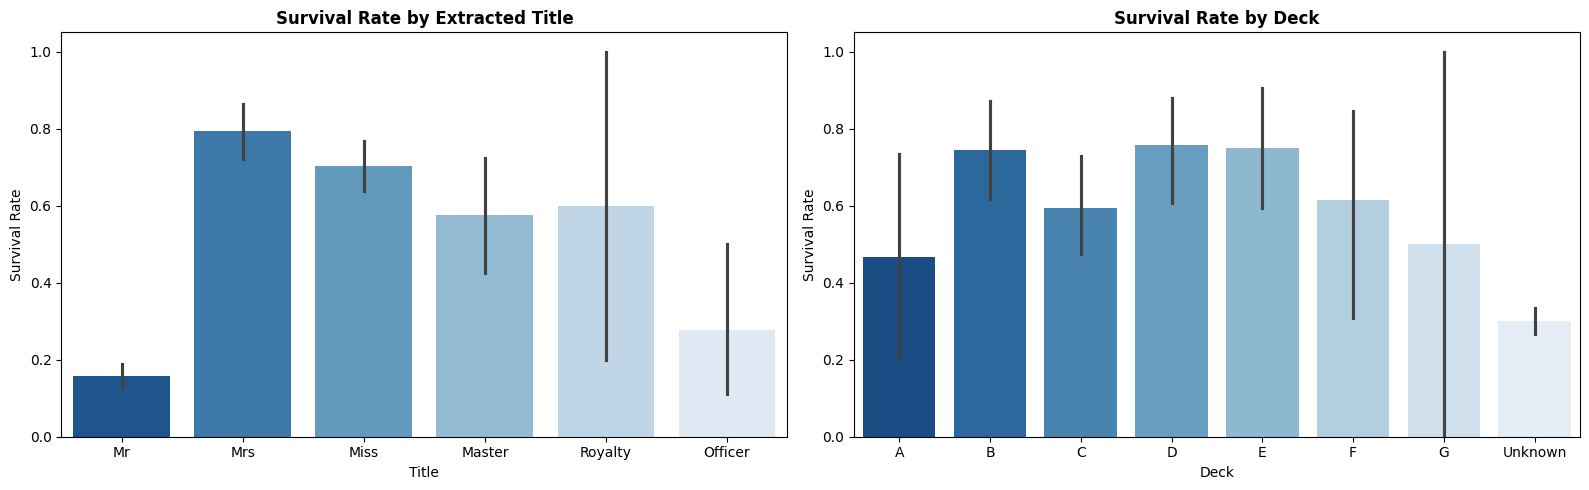

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=engineered_df, x="Title", y="Survived", palette="Blues_r", ax=axes[0])
axes[0].set_title("Survival Rate by Extracted Title", fontweight="bold")
axes[0].set_ylabel("Survival Rate")

sns.barplot(data=engineered_df, x="Deck", y="Survived", order=["A", "B", "C", "D", "E", "F", "G", "Unknown"], palette="Blues_r", ax=axes[1])
axes[1].set_title("Survival Rate by Deck", fontweight="bold")
axes[1].set_ylabel("Survival Rate")

plt.tight_layout()
plt.show()


## 3. Feature Correlation Heatmap

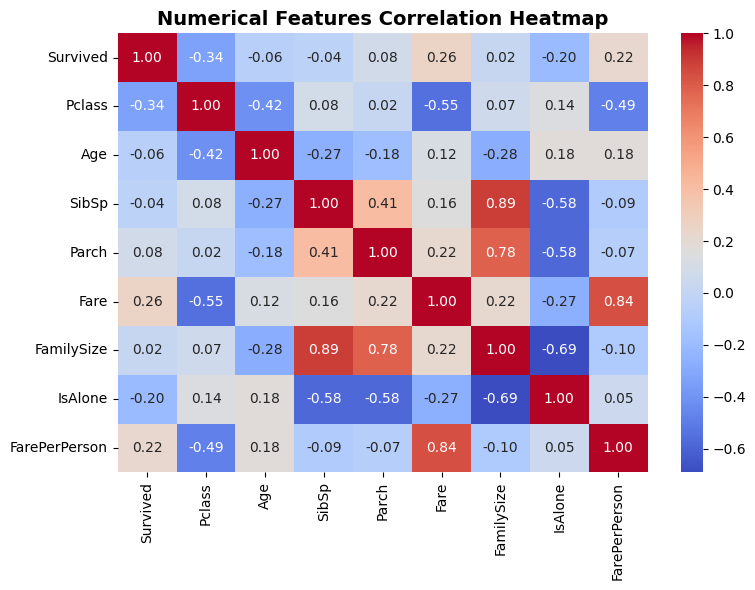

In [4]:
# Correlation for numerical features
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "FarePerPerson"]
corr_matrix = engineered_df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax)
ax.set_title("Numerical Features Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Export Processed Clean Dataset

In [5]:
# Save clean dataset for training
save_path = save_processed_data(engineered_df, "../data/processed/titanic_clean.csv")
print(f"Clean processed dataset successfully saved to: {save_path}")


Clean processed dataset successfully saved to: ..\data\processed\titanic_clean.csv
